# Grouping tumor solids by the uniformity of selected cell types

Same as the tumor_solid_analysis tutorial, but with **only the cell types you choose**:

- `scomv.solid_cell_uniformity(grid, solid, cell_df, cell_types)` → solids × the selected cell types
  (distance-weighted uniformity, 10–100 µm).
- `scomv.cluster_solids(features, columns=...)` → groups from any subset of the columns (Gaussian mixture with k by
  BIC, or Ward with a fixed k).

## 1. Data, grid and solids

In [1]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scanpy as sc
import stlearn as st
import scomv
from scomv.preparation.skny_calc_distance import calculate_distance

adata = st.ReadXenium(
    feature_cell_matrix_file="../tutorial_data/xenium_data/cell_feature_matrix.h5",
    cell_summary_file="../tutorial_data/xenium_data/cells.csv.gz",
    library_id="example data", image_path=None, scale=1, spot_diameter_fullres=10,
)
sc.pp.filter_genes(adata, min_cells=300)

# 10 µm grid and SKNY tumor boundary (CDH1 / EPCAM)
N_COL = int((adata.obs.imagecol.max() - adata.obs.imagecol.min()) / 10)
N_ROW = int((adata.obs.imagerow.max() - adata.obs.imagerow.min()) / 10)
grid = st.tl.cci.grid(adata, n_row=N_ROW, n_col=N_COL, n_cpus=10, verbose=False)
grid = calculate_distance(grid, pos_marker_ls=["CDH1", "EPCAM"])
sc.pp.filter_cells(adata, min_genes=10)

[calculate_distance] N_ROW=547, N_COL=752, positive cells in grid=100012/411344


Calculating gene expression of (-∞, 0]


40 tumor solids


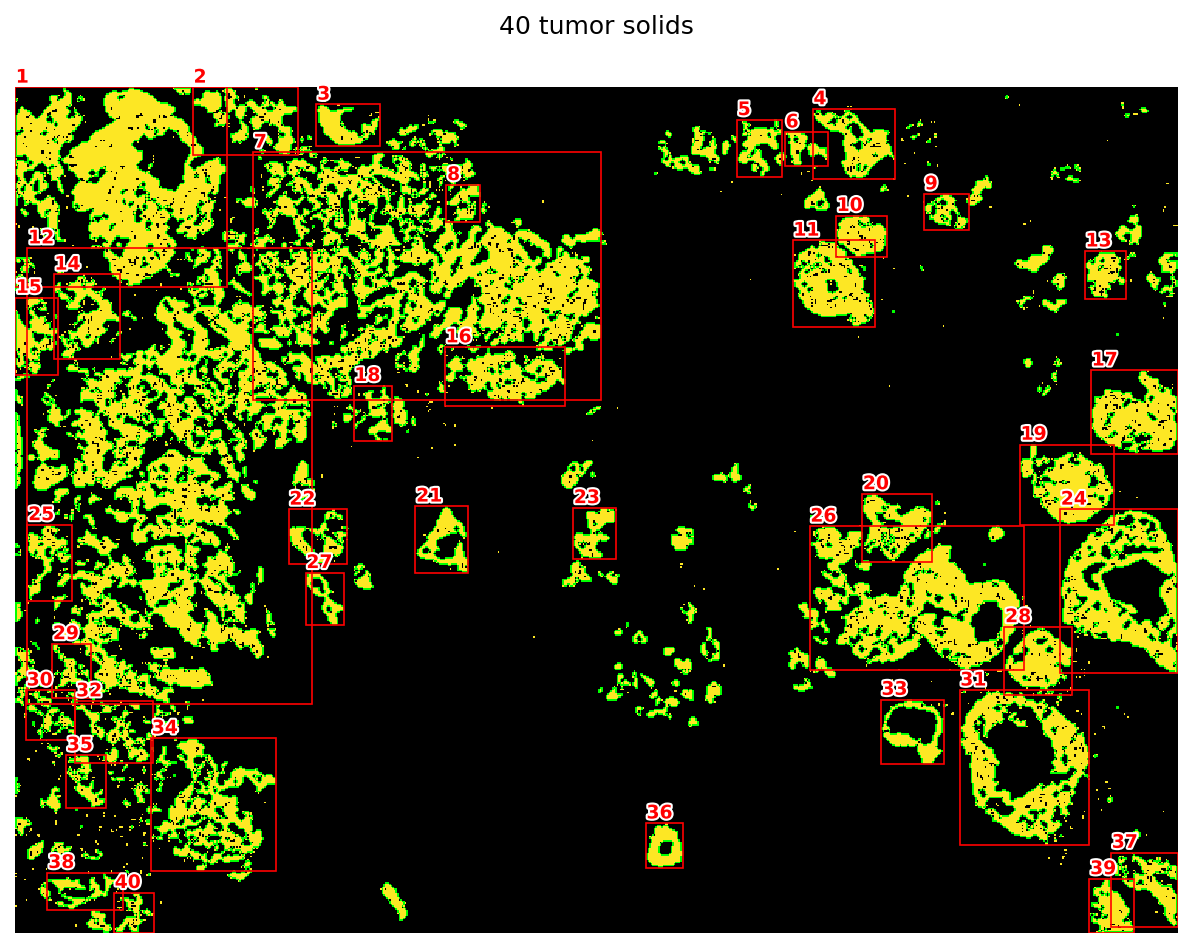

In [2]:
from scomv.tumor_solid import extract_tumor_solids, label_solid_regions, plot_tumor_solids, plot_cluster_map

MIN_AREA = 250   # minimum solid area (grid squares)
solid = extract_tumor_solids(grid, section_um=None, min_area=MIN_AREA)
labels_img, _, _ = label_solid_regions(grid, min_area=MIN_AREA)
print(f"{len(solid.obs)} tumor solids")
plot_tumor_solids(solid, title=f"{len(solid.obs)} tumor solids")
plt.show()

## 2. Cell annotation (dataset-specific mapping to broad types, as in tumor_solid_analysis)

In [3]:
cell_ann = pd.read_excel("../tumor_solid_analysis/cell.xlsx").set_index("Barcode")
obs = adata.obs[["imagecol", "imagerow"]].copy()
obs.index = obs.index.astype(int)
cell_df = pd.concat([obs, cell_ann[["Cluster"]]], axis=1).dropna()

BROAD_MAP = {"B_Cells": "B cells", "CD4+_T_Cells": "CD4+ T cells", "CD8+_T_Cells": "CD8+ T cells",
             "Macrophages_1": "Macrophages / monocytes", "Macrophages_2": "Macrophages / monocytes",
             "IRF7+_DCs": "Dendritic cells", "LAMP3+_DCs": "Dendritic cells", "Stromal": "Fibroblasts",
             "Endothelial": "Endothelial cells", "Perivascular-Like": "Endothelial cells"}
cell_df["Cluster"] = cell_df["Cluster"].map(BROAD_MAP)
cell_df = cell_df.dropna()
cell_df["Cluster"].value_counts()

Cluster
Fibroblasts                41401
Macrophages / monocytes    12781
Endothelial cells           9776
CD4+ T cells                8431
CD8+ T cells                6937
B cells                     4979
Dendritic cells              792
Name: count, dtype: int64

## 3. Select the cell types

In [4]:
CELL_TYPES = ["CD8+ T cells", "CD4+ T cells", "Macrophages / monocytes", "Fibroblasts", "Endothelial cells"]
cell_u = scomv.solid_cell_uniformity(grid, solid, cell_df, CELL_TYPES)
cell_u.head()

cell_type,CD8+ T cells,CD4+ T cells,Macrophages / monocytes,Fibroblasts,Endothelial cells
solid,,,,,
1,0.634607,0.609696,0.799760,0.869762,0.722191
2,0.097925,0.202349,0.476966,0.693300,0.388071
3,0.040722,0.079224,0.240324,0.489522,0.156743
4,0.482521,0.480064,0.510911,0.746336,0.381330
5,0.552969,0.517078,0.596599,0.659428,0.187561


cell_type  n_solids  mean CD8+ T cells  mean CD4+ T cells  mean Macrophages / monocytes  mean Fibroblasts  mean Endothelial cells
group                                                                                                                            
G1               11              0.066              0.029                         0.172             0.548                   0.170
G2               18              0.149              0.094                         0.328             0.794                   0.332
G3                5              0.471              0.405                         0.584             0.747                   0.281
G4                6              0.525              0.460                         0.799             0.892                   0.715


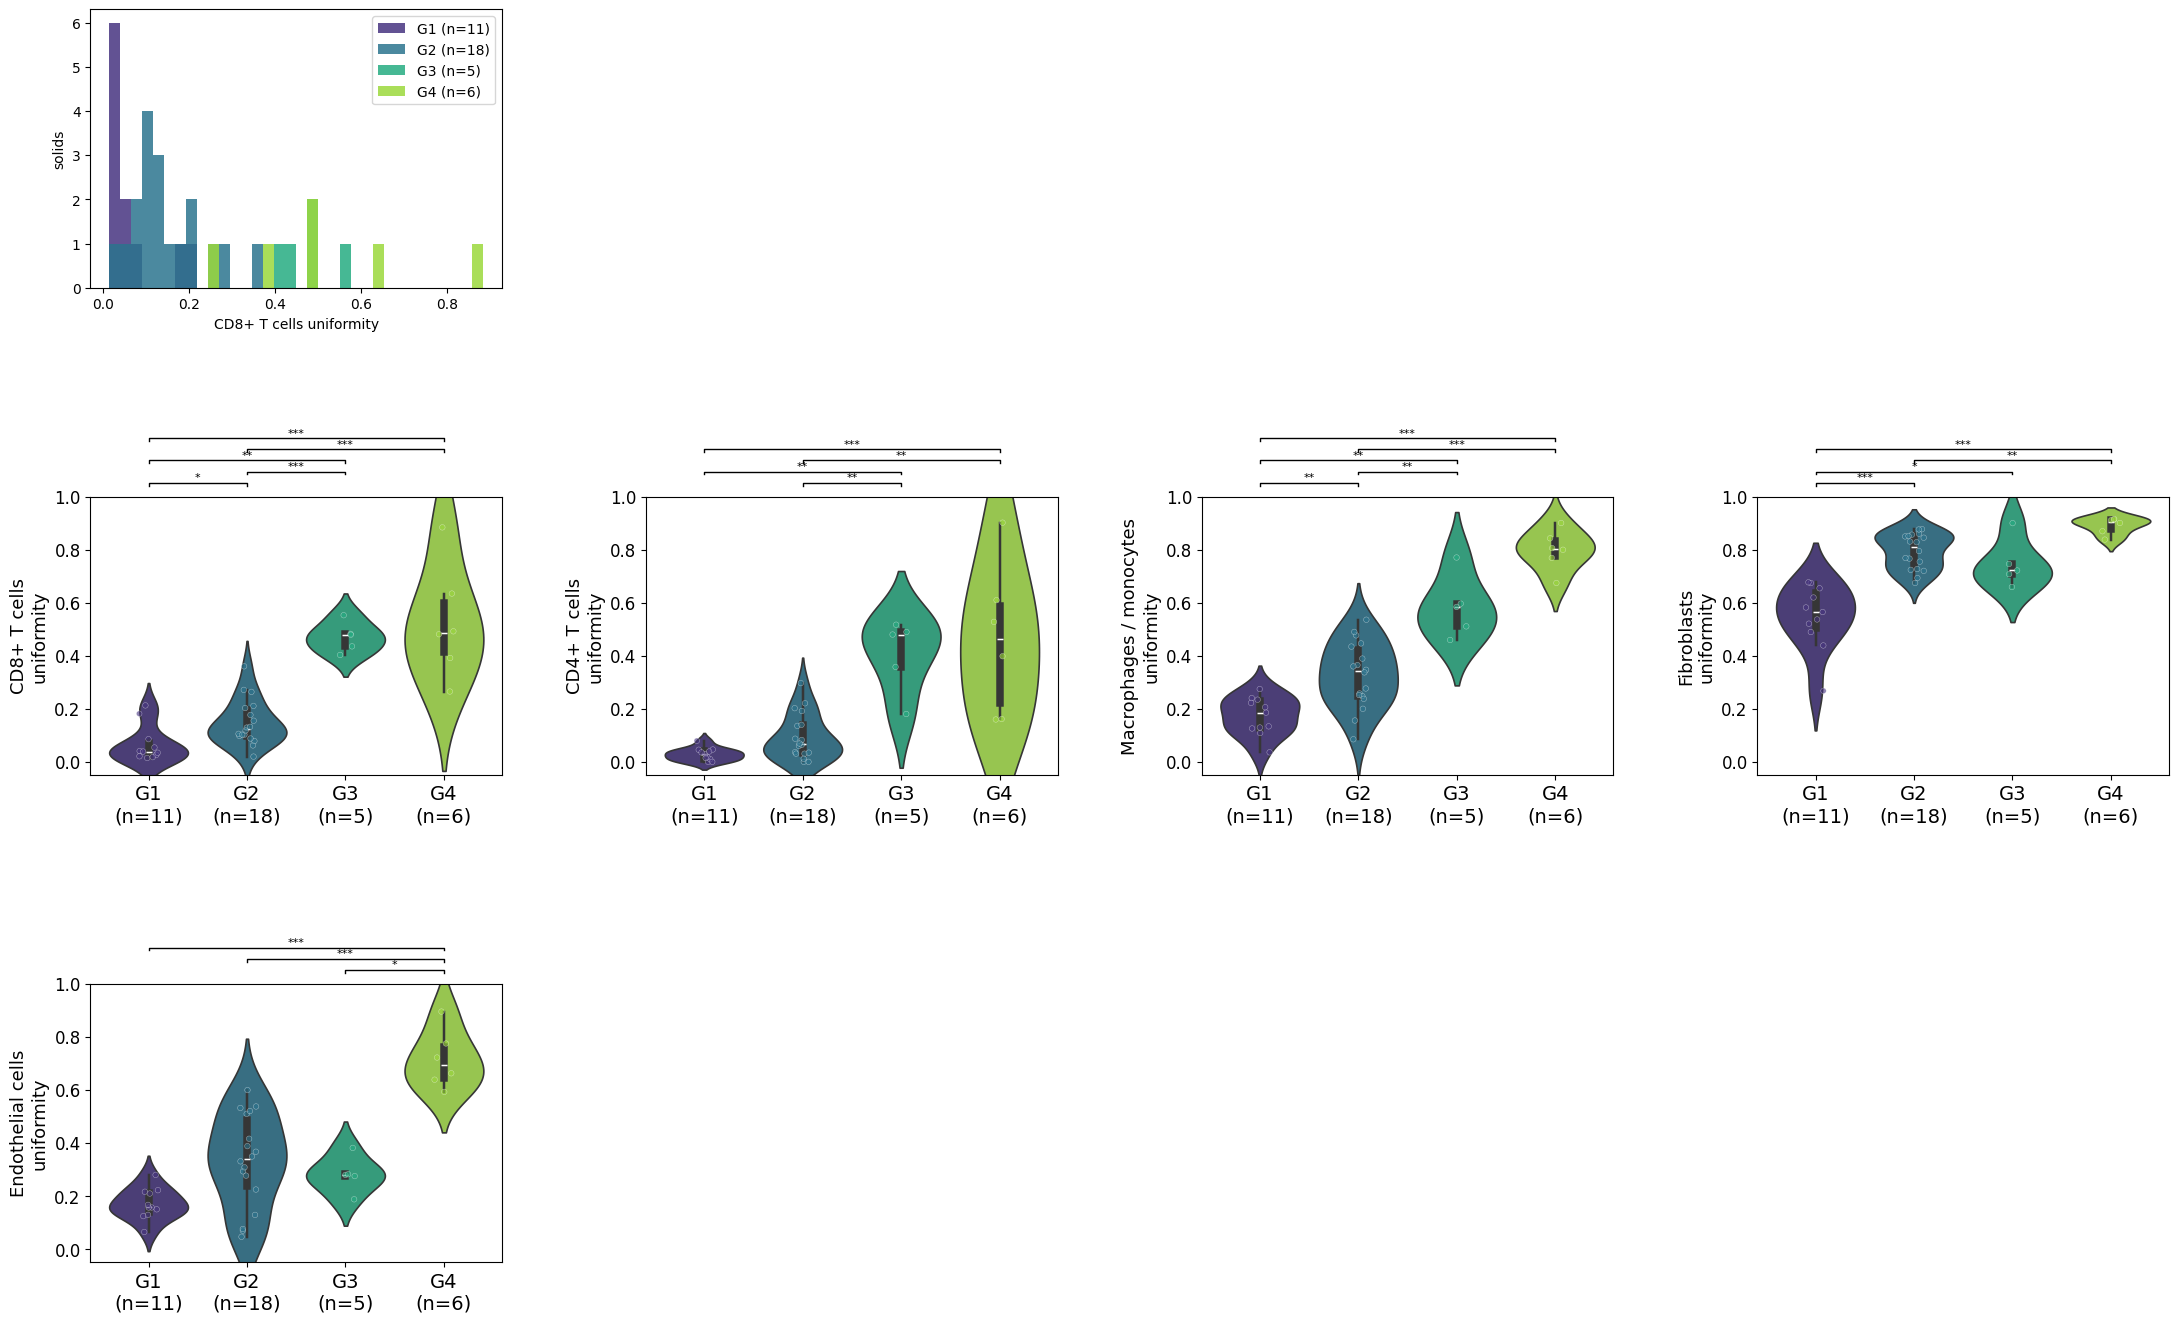

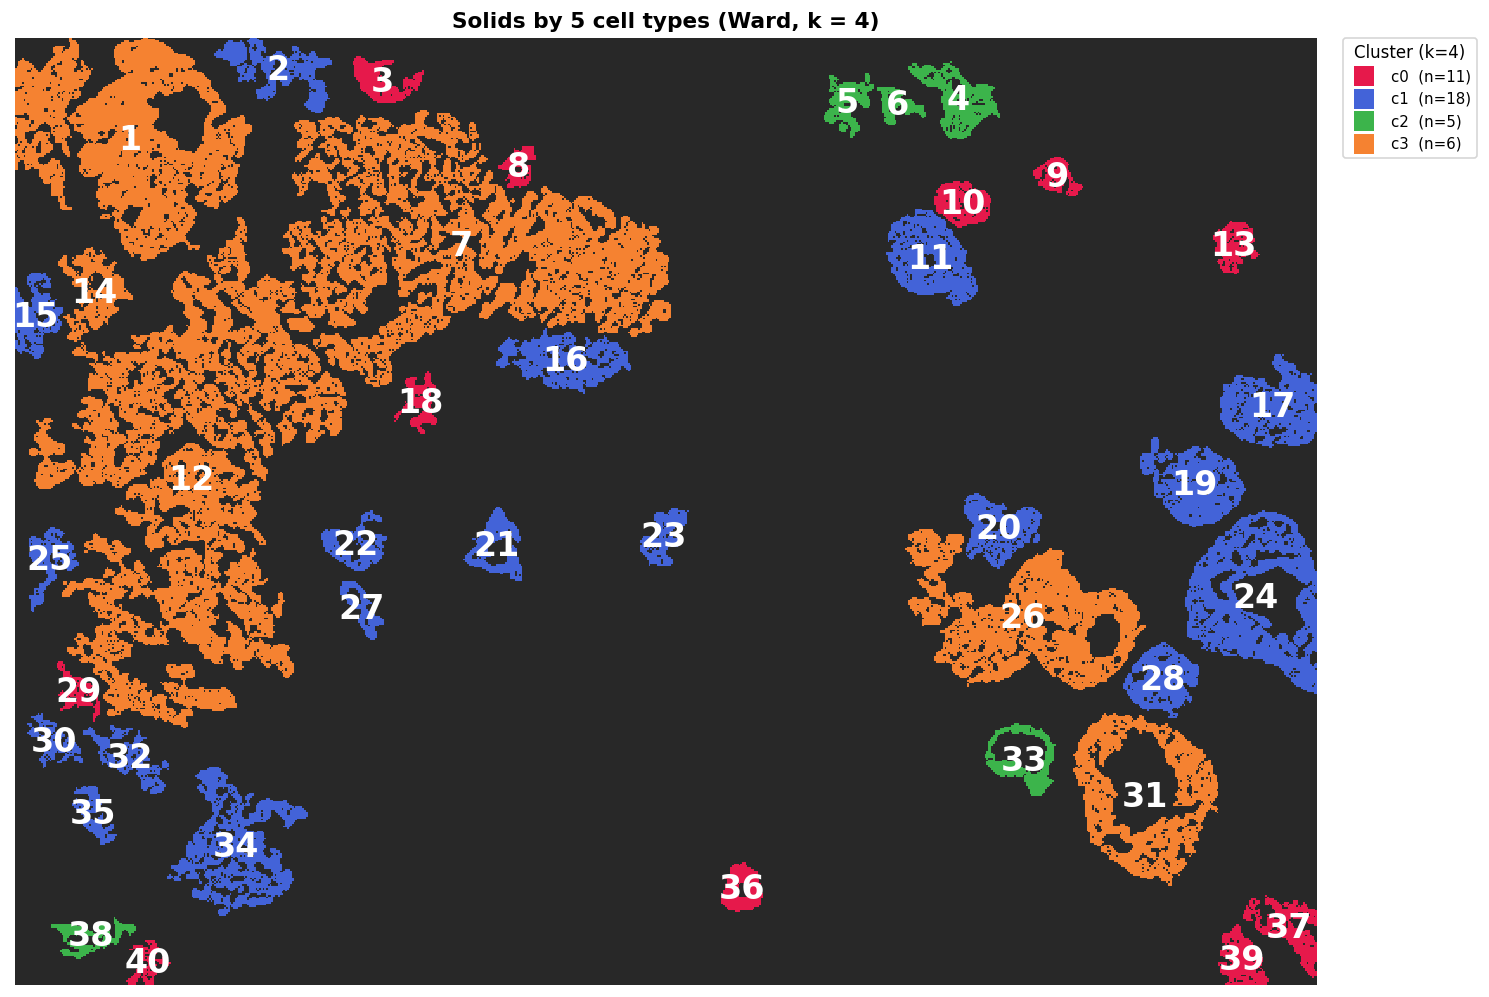

In [5]:
groups = scomv.cluster_solids(cell_u, method="ward", n_clusters=4, order_by="CD8+ T cells")
scomv.plot_solid_clusters(groups)
plt.show()
plot_cluster_map(labels_img, solid.obs, groups.cluster_of_solid, n_clusters=groups.k,
                 title="Solids by 5 cell types (Ward, k = 4)")
plt.show()

Only the immune cells (a subset of the computed columns), number of groups by BIC:

BIC choice: k = 6
cell_type  n_solids  mean CD8+ T cells  mean CD4+ T cells  mean Macrophages / monocytes
group                                                                                  
G1               23              0.102              0.039                         0.223
G2                4              0.123              0.150                         0.487
G3                3              0.325              0.292                         0.390
G4                3              0.398              0.167                         0.720
G5                6              0.504              0.504                         0.699
G6                1              0.884              0.902                         0.901


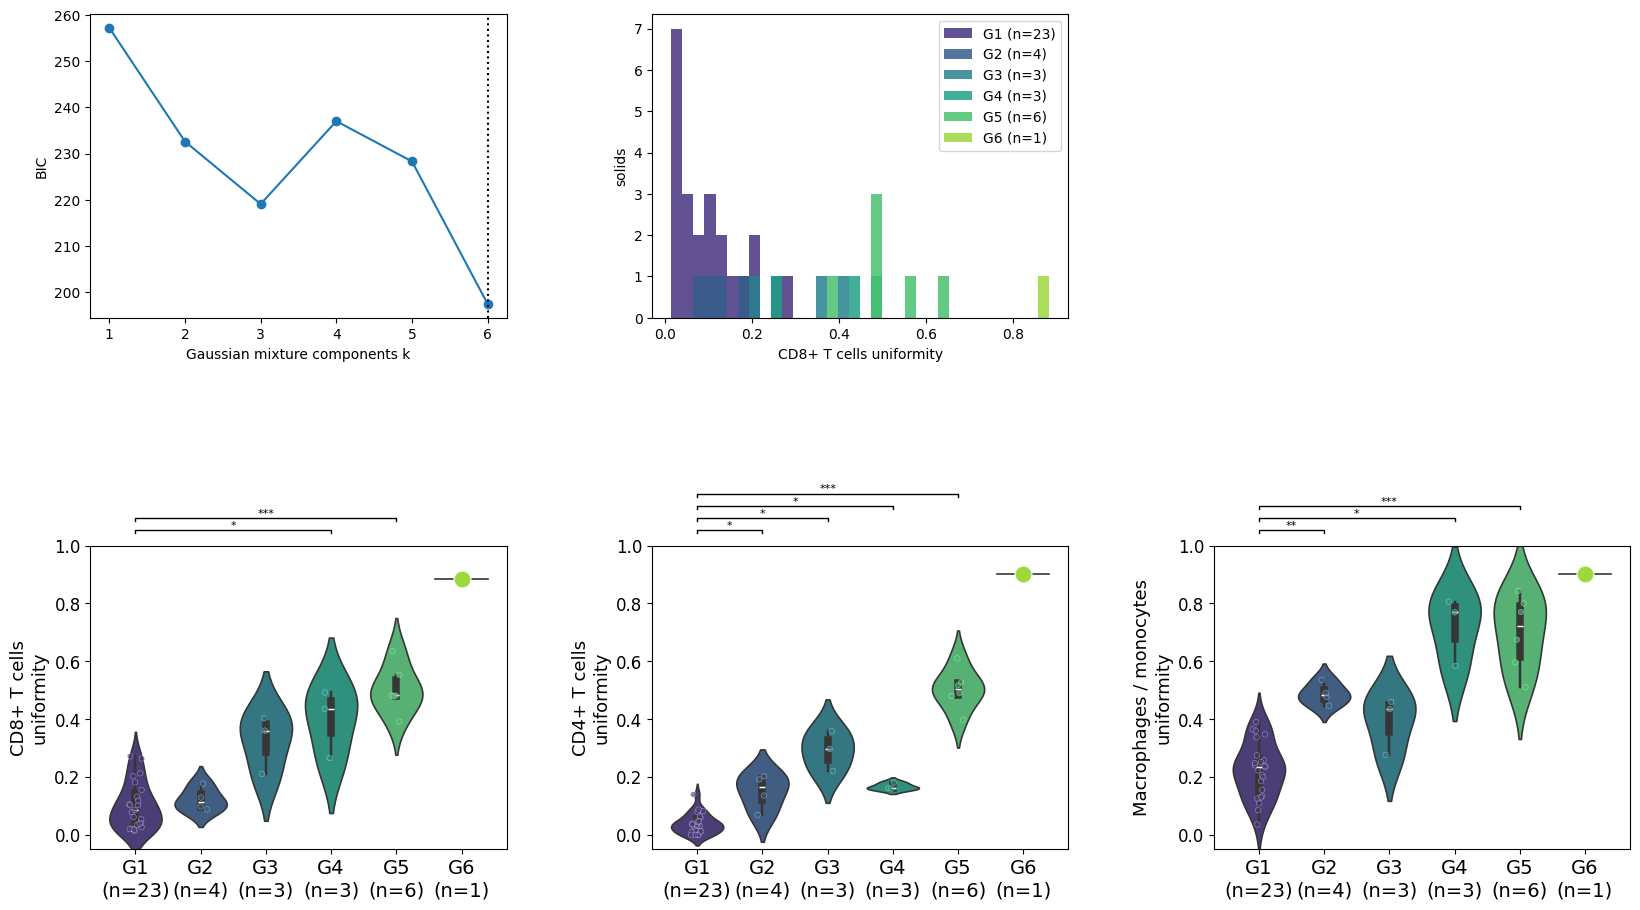

In [6]:
immune = scomv.cluster_solids(cell_u, columns=["CD8+ T cells", "CD4+ T cells", "Macrophages / monocytes"])
scomv.plot_solid_clusters(immune)
plt.show()

## 4. Cells and genes together

uniformity of 1 gene(s) around 40 solids (size factor: median 0.93, range 0.31-13.33)
       n_solids  mean CD8+ T cells  mean POSTN
group                                         
low           8              0.057       0.694
mid          21              0.136       0.806
high         11              0.509       0.801


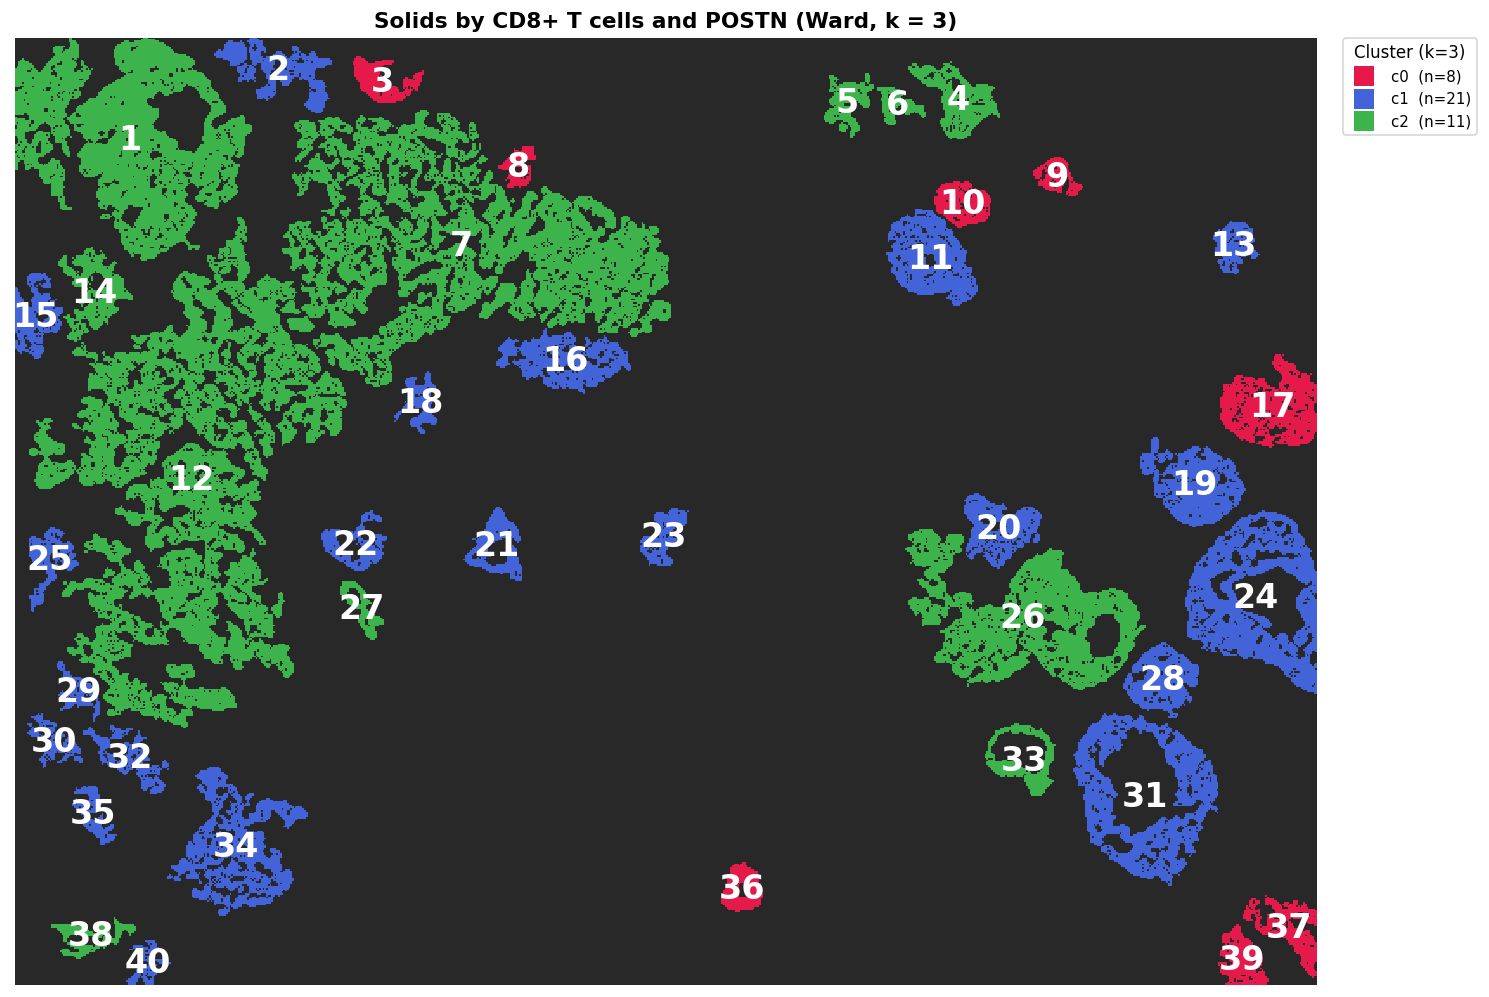

In [7]:
both = cell_u.join(scomv.solid_gene_uniformity(grid, solid, ["POSTN"]))
mixed = scomv.cluster_solids(both, columns=["CD8+ T cells", "POSTN"], method="ward", n_clusters=3)
plot_cluster_map(labels_img, solid.obs, mixed.cluster_of_solid, n_clusters=mixed.k,
                 title="Solids by CD8+ T cells and POSTN (Ward, k = 3)")
plt.show()